# Comparison between GNSS, Distributed Acoustic Sensing & Fiber Bragg Grating

## Import modules

In [53]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import medfilt, detrend
import glob
import os
import xarray as xr
from tqdm import tqdm
from obspy.signal.filter import highpass, lowpass, bandpass
from scipy.signal import tukey, detrend

In [54]:
path_plots = '../../plots/GNSS_DAS_FBG_comparison/'

if not os.path.exists(path_plots):
    os.makedirs(path_plots)

In [55]:
path_gnss = '../../data/GNSS/'

if not os.path.exists(path_gnss):
    os.makedirs(path_gnss)

## Import Fiber Bragg Grating data

### Import SP-5.2 : Tilted strain-pad

In [112]:
ds = xr.open_dataset("../../../fbg_data_r/gunnvher_channel_5_fbg.nc")

### Import T-2.xx : Temperature sensors

In [57]:
ds_hor = xr.open_dataset('../../../fbg_data_r/gunnvher_channel_2_fbg_cleaned_10s.nc')

## Importing DAS data

In [58]:
das_data = xr.open_dataset('../../../DAS_Caltech/3_das_strain_2025_feb13_may19_proc_ch_2000_2150.h5')
#das_data = xr.open_dataset('/home/geophysic/jgovoort/fbg_gunnuvher/DAS_Caltech/no_med_strain/3_das_strain_2025-02-13T09:52:17_2025-05-19T00:24:57.h5')

## Earthquakes catalogue

In [97]:
imo_eq = pd.read_csv('../../data/EQ_IMO/eq_imo_01042025.csv', index_col="time", parse_dates=True)

In [98]:
imo_eq

,quakeId,magnitude,depth,region,lat,lon
time,,,,,,
2025-04-01 23:55:34.495,SIL1378111,1.55,2.329,NaN,63.78205,-22.71901
2025-04-01 23:54:53.263,SIL1378112,1.09,4.207,NaN,63.97001,-22.11204
2025-04-01 23:54:20.735,SIL1378117,1.67,5.274,NaN,63.94176,-22.24963
2025-04-01 23:53:34.750,SIL1378115,1.41,5.000,NaN,63.94706,-22.25594
2025-04-01 23:53:05.418,SIL1378113,2.00,5.580,NaN,63.94307,-22.27451
...,...,...,...,...,...,...
2025-03-31 00:18:14.163,SIL1374118,2.08,6.615,NaN,64.03465,-21.55540
2025-03-31 00:11:54.680,SIL1374117,0.63,5.700,NaN,64.03610,-21.55708
2025-03-31 00:10:11.335,SIL1374115,1.35,5.495,NaN,64.03497,-21.54556


## GNSS

### Download GNSS data and move to dedicated folder

In [59]:
# Download the data
#! wget https://cdn.vedur.is/gps/timeseries/data/post-processing/timeseries/SAFH-plate.NEU
#! wget https://cdn.vedur.is/gps/timeseries/data/post-processing/timeseries/HAFC-plate.NEU
! wget https://cdn.vedur.is/gps/timeseries/data/post-processing/timeseries/RVIT-plate.NEU
#! wget https://cdn.vedur.is/gps/timeseries/data/post-processing/timeseries/VMOS-plate.NEU
! wget https://cdn.vedur.is/gps/timeseries/data/post-processing/timeseries/SYRF-plate.NEU


--2026-10-09 14:47:32--  https://cdn.vedur.is/gps/timeseries/data/post-processing/timeseries/RVIT-plate.NEU
Resolving cdn.vedur.is (cdn.vedur.is)... 130.208.86.10
Connecting to cdn.vedur.is (cdn.vedur.is)|130.208.86.10|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 135733 (133K) [application/octet-stream]
Saving to: ‘RVIT-plate.NEU’

RVIT-plate.NEU      100%[===================>] 132,55K  --.-KB/s    in 0,1s    

2026-10-09 14:47:33 (931 KB/s) - ‘RVIT-plate.NEU’ saved [135733/135733]

--2026-10-09 14:47:33--  https://cdn.vedur.is/gps/timeseries/data/post-processing/timeseries/SYRF-plate.NEU
Resolving cdn.vedur.is (cdn.vedur.is)... 130.208.86.10
Connecting to cdn.vedur.is (cdn.vedur.is)|130.208.86.10|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 146909 (143K) [application/octet-stream]
Saving to: ‘SYRF-plate.NEU’

SYRF-plate.NEU      100%[===================>] 143,47K  --.-KB/s    in 0,1s    

2026-10-09 14:47:34 (1024 KB/s) - ‘SYRF

In [60]:
! mv *.NEU ../../data/GNSS/

### Import data

In [61]:
# Read the data
RVIT = pd.read_csv(path_gnss + '/RVIT-plate.NEU', delim_whitespace=True, index_col='#yyyy/mm/dd')
SYRF = pd.read_csv(path_gnss + '/SYRF-plate.NEU', delim_whitespace=True, index_col='#yyyy/mm/dd')

### Reindex

In [62]:
def reindex(df, time):
    df.index = pd.to_datetime(df.index, format='%Y/%m/%d')
    df.index.name = 'Time'
    df = df[~df.index.duplicated()]
    df = df.sort_index()
    return df.reindex(time)

In [63]:
time = pd.date_range(start='2023-01-01', end='2025-09-01', freq='1D')

In [64]:
RVIT = reindex(RVIT, time)
SYRF = reindex(SYRF, time)

### Demeaning

In [65]:
rvit_n = RVIT['dN[mm]']
rvit_e = RVIT['dE[mm]']
rvit_u = RVIT['dU[mm]']

syrf_n = SYRF['dN[mm]']
syrf_e = SYRF['dE[mm]']
syrf_u = SYRF['dU[mm]']

rvit_n = rvit_n - np.nanmean(rvit_n)
rvit_e = rvit_e - np.nanmean(rvit_e)
rvit_u = rvit_u - np.nanmean(rvit_u)

syrf_n = syrf_n - np.nanmean(syrf_n)
syrf_e = syrf_e - np.nanmean(syrf_e)
syrf_u = syrf_u - np.nanmean(syrf_u)

err_rvit_n = RVIT['DN[mm]']
err_rvit_e = RVIT['DE[mm]']
err_rvit_u = RVIT['DU[mm]']

err_syrf_n = SYRF['DN[mm]']
err_syrf_e = SYRF['DE[mm]']
err_syrf_u = SYRF['DU[mm]']


Text(0, 0.5, 'Displacement [mm]')

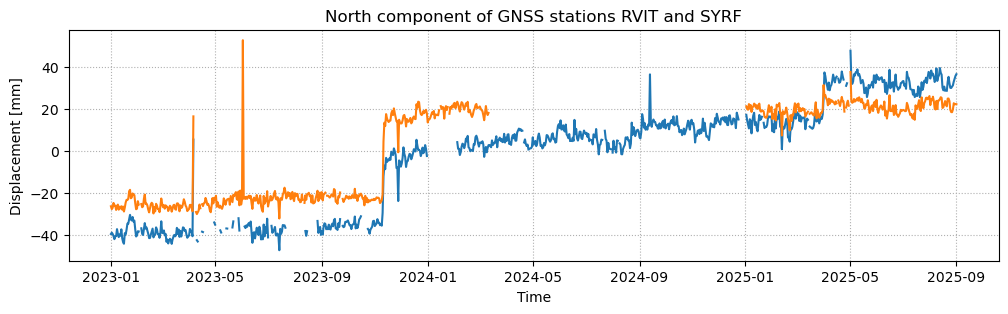

In [66]:
plt.figure(figsize=(12, 3))
plt.plot(time, rvit_n)
plt.plot(time, syrf_n)
plt.grid(ls=':')
plt.title('North component of GNSS stations RVIT and SYRF')
plt.xlabel('Time')
plt.ylabel('Displacement [mm]')

## Comparison GNSS, DAS, FBG

In [113]:
data = ds.Wavelength_nm.sel(FBG=1)
#daterange = np.arange(np.datetime64('2025-03-01'), np.datetime64('2025-05-01'), np.timedelta64(2, 's'))
#data = data.reindex(daterange)


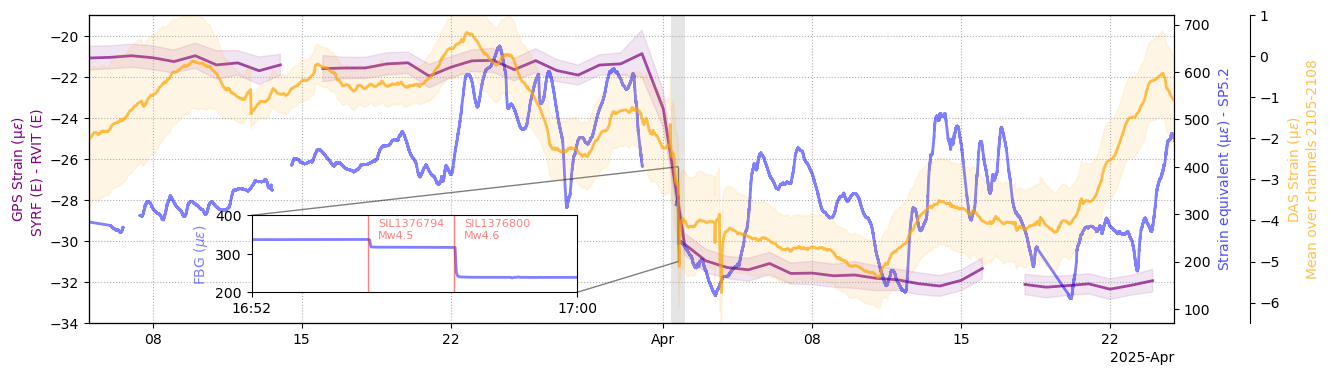

In [136]:
#%matplotlib widget
zoom = True
dl = -1
%matplotlib inline

ch1, ch2 =  2105, 2108

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(14,4), sharex=True)


distance_rvit_syrf = 3313.62  # in meters
strain_gps = ((syrf_e - rvit_e)/1000)/distance_rvit_syrf * 1e6  # in microstrain

error = np.sqrt((err_syrf_e/1000/distance_rvit_syrf * 1e6)**2 + (err_rvit_e/1000/distance_rvit_syrf * 1e6)**2)

ax.plot(strain_gps, color='purple', alpha=.7, lw=2)
ax.set_ylim(-33+dl, -18+dl)

ax.fill_between(time, strain_gps - error, strain_gps + error, color='purple', alpha=.1)

axb = ax.twinx()
axdas = ax.twinx()
data_ = (data  - data.mean())*1000 # convert to pm and remove mean
data_.plot(ax=axb, color='blue', alpha=.5, lw=2)
axb.set_ylim(100+dl*30, 750+dl*30)
#ax.set_ylim(8, 23)
ax.set_xlim(np.datetime64('2025-03-05'), np.datetime64('2025-04-25'))
das_data.strain.sel(channel=slice(ch1,ch2)).mean(dim='channel').plot(ax=axdas, color='orange', alpha=.7, lw=2)
axdas.fill_between(das_data.time, das_data.strain.sel(channel=slice(ch1,ch2)).mean(dim='channel') - das_data.strain.sel(channel=slice(ch1,ch2)).std(dim='channel'),
                   das_data.strain.sel(channel=slice(ch1,ch2)).mean(dim='channel') + das_data.strain.sel(channel=slice(ch1,ch2)).std(dim='channel'), color='orange', alpha=.1)
axdas.spines.right.set_position(("axes", 1.07))
#axdas.set_ylim(-5.5,1.5)
axdas.set_ylabel('DAS Strain (µ$\epsilon$)\nMean over channels %d-%d' % (ch1, ch2), color='orange', alpha=.7, zorder=.1)

axdas.set_ylim(-5.5+dl ,2+dl)
ax.fill_betweenx([-40, -10], np.datetime64('2024-08-22T21:26'), np.datetime64('2024-09-06T00:00'), facecolor='grey', alpha=.2)
ax.fill_betweenx([-40, -10], np.datetime64('2024-11-21T00:14'), np.datetime64('2024-12-02T00:00'), facecolor='grey', alpha=.2)
ax.fill_betweenx([-40, -10], np.datetime64('2025-04-01T09:15'), np.datetime64('2025-04-02T00:00'), facecolor='grey', alpha=.2)
ax.grid(ls=':')
'''
axins = ax.inset_axes(
    [0.01, 0.1, 0.3, 0.3],
    xlim=(np.datetime64('2025-04-01T14'), np.datetime64('2025-04-02')), ylim=(-110, -80), xticklabels=[], yticklabels=[])
#axins.plot(df.index,bandpassed_bareV,c='black', lw=0.5)
ax.indicate_inset_zoom(axins, edgecolor="r")
axins.set_ylim(-6,-2)
axbins = axins.twinx()
das_data.strain.sel(channel=slice(ch1,ch2)).mean(dim='channel').plot(ax=axins, color='k', alpha=.5, lw=2)
data_.plot(ax=axbins, color='red', alpha=.5, lw=0.9)
axbins.set_ylim(1537, 1537.30)
axins.set_xticks([np.datetime64('2025-04-01T14'), np.datetime64('2025-04-01T20'), np.datetime64('2025-04-02T00')])
'''
if zoom:
    t1, t2 = '16:52', '17:00'
    ax_zoom = ax.inset_axes([0.15, 0.1, 0.3, 0.25])
    ax_zoom.set_xlim(np.datetime64('2025-04-01T%s'%t1), np.datetime64('2025-04-01T%s'%t2))
    data_.plot(ax=ax_zoom, color='blue', alpha=.5, lw=2)
    ax_zoom.set_ylabel('FBG ($\mu \epsilon$)', color='blue', alpha=.5, zorder=.1)
    ax_zoom.set_ylim(200, 400)
    for eq_time in imo_eq.index :
        if imo_eq.loc[eq_time, 'magnitude'] > 4:
            ax_zoom.axvline(np.datetime64(eq_time) - np.timedelta64(2, 'h'), color='r', alpha=.5, lw=1)
            ax_zoom.text(np.datetime64(eq_time) - np.timedelta64(120*60 - 15, 's'), 340, imo_eq.loc[eq_time, 'quakeId'] + '\nMw%.1f' % imo_eq.loc[eq_time, 'magnitude'], color='r', alpha=.5, fontsize=8)
    ax_zoom.set_xlabel('')
    axb.indicate_inset_zoom(ax_zoom, edgecolor="k")
    ax_zoom.set_facecolor('white')
    ax_zoom.set_xticks([np.datetime64('2025-04-01T%s'%t1), np.datetime64('2025-04-01T%s'%t2)], labels=[t1, t2])
ax.set_ylabel('GPS Strain (µ$\epsilon$)\nSYRF (E) - RVIT (E) ', color='purple')
axb.set_ylabel('Strain equivalent (µ$\epsilon$) - SP5.2', color='blue', alpha=.7)

plt.savefig(path_plots + 'strain_comparison_RVIT_SYRF_FBG_DAS.png', dpi=300, bbox_inches='tight')
plt.show()